# **Raw Dataset Exploratory Data Analysis (EDA)**

This Exploratory Data Analysis (EDA) notebook aims to examine the raw data to inform the feature engineering and labelling process.

## **Load Dataset & Dependencies**

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style

In [2]:
sheets = pd.read_excel("../data/raw/online_retail_II.xlsx", sheet_name=["Year 2009-2010", "Year 2010-2011"])
df = pd.concat(sheets.values(), ignore_index=True)

In [3]:
# Style and font size for graphical EDA visualisations
style.use("ggplot")
FIGURE_TITLE = 14
GRAPH_TITLE = 12
AXIS_LABELS = 8
TICKS = 6

## **Dataset Overview**

### **Full Dataset (Unidentified and Identified Customers)**

In [4]:
print(f"DataFrame Shape: {df.shape}")
df.info()

DataFrame Shape: (1067371, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [5]:
# Changed all column headers to snake_case for better style integration with Python EDA
COLUMN_MAP = {
    "Invoice": "invoice",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "price",
    "Customer ID": "customer_id",
    "Country": "country",
}
df.columns = df.columns.str.strip()
df = df.rename(columns=COLUMN_MAP)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column        Non-Null Count    Dtype         
---  ------        --------------    -----         
 0   invoice       1067371 non-null  object        
 1   stock_code    1067371 non-null  object        
 2   description   1062989 non-null  object        
 3   quantity      1067371 non-null  int64         
 4   invoice_date  1067371 non-null  datetime64[us]
 5   price         1067371 non-null  float64       
 6   customer_id   824364 non-null   float64       
 7   country       1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [7]:
df.describe()

,quantity,invoice_date,price,customer_id
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [8]:
df.describe(include="string")

,country
count,1067371
unique,43
top,United Kingdom
freq,981330


In [9]:
df.head(10)

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


**Dataset Summary and Column Header Descriptions (from UCI Machine Learning Repository Website):**

Online Retail II contains all the transactions occurring for a UK-based and registered, non-store online retail between 01/12/2009 and 09/12/2011. The company mainly sells unique all-occasion gift-ware. Many customers of the company are wholesalers.

| Column | Description |
|--------|-------------|
| invoice | Invoice number. Nominal. A 6-digit integral number uniquely assigned to each transaction. If this code starts with the letter 'C', it indicates a cancellation. |
| stock_code | Product (item) code. Nominal. A 5-digit integral number uniquely assigned to each distinct product. |
| description | Product (item) name. Nominal. |
| quantity | The quantities of each product (item) per transaction. Numeric. |
| invoice_date | Invice date and time. Numeric. The day and time when a transaction was generated. |
| price | Unit price. Numeric. Product price per unit in sterling (Â£). |
| customer_id | Customer number. Nominal. A 5-digit integral number uniquely assigned to each customer. |
| country | Country name. Nominal. The name of the country where a customer resides. |


### **Duplicate Analysis and Filtration**

In [10]:
print(f"Total number of duplicate rows: {df.duplicated().sum()}")

Total number of duplicate rows: 34335


In [11]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

### **Missing Value Analysis**

In [12]:
df.isna().sum()

invoice              0
stock_code           0
description       4275
quantity             0
invoice_date         0
price                0
customer_id     235151
country              0
dtype: int64

In [13]:
df[df["description"].isna()].describe()

,quantity,invoice_date,price,customer_id
count,4275.000000,4275,4275.0,0.0
mean,-17.366784,2010-09-17 17:48:07.480701,0.0,NaN
min,-9600.000000,2009-12-01 11:44:00,0.0,NaN
25%,-28.000000,2010-03-08 15:32:00,0.0,NaN
50%,-4.000000,2010-08-13 11:46:00,0.0,NaN
75%,3.000000,2011-03-24 10:48:00,0.0,NaN
max,9600.000000,2011-12-08 14:06:00,0.0,NaN
std,515.938734,NaN,0.0,NaN


**Note on Missing Value Analysis:** All the rows with NaN values for "description" also have NaN values for "customer_id". As the customers with NaN values for "customer_id" cannot be identified for churn prediction, all such rows (including those where "description" is listed as NaN) will be dropped. This means that there are effectively 0 raw NaN values in the dataset that require imputing.

### **Filtered Dataset (Identified Customers)**

In [14]:
df_identified = df.dropna(axis=0, how="any", subset="customer_id", inplace=False, ignore_index=True).sort_values("invoice_date")
print(f"Number of rows dropped: {df.shape[0] - df_identified.shape[0]}")
df_identified.isna().sum()

Number of rows dropped: 235151


invoice         0
stock_code      0
description     0
quantity        0
invoice_date    0
price           0
customer_id     0
country         0
dtype: int64

In [15]:
df_identified.info()

<class 'pandas.DataFrame'>
Index: 797885 entries, 0 to 797884
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   invoice       797885 non-null  object        
 1   stock_code    797885 non-null  object        
 2   description   797885 non-null  object        
 3   quantity      797885 non-null  int64         
 4   invoice_date  797885 non-null  datetime64[us]
 5   price         797885 non-null  float64       
 6   customer_id   797885 non-null  float64       
 7   country       797885 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.0+ MB


In [16]:
df_identified.describe()

,quantity,invoice_date,price,customer_id
count,797885.000000,797885,797885.000000,797885.000000
mean,12.602980,2011-01-02 13:17:34.141161,3.702732,15313.062777
min,-80995.000000,2009-12-01 07:45:00,0.000000,12346.000000
25%,2.000000,2010-07-02 09:47:00,1.250000,13964.000000
50%,5.000000,2010-12-02 12:33:00,1.950000,15228.000000
75%,12.000000,2011-07-31 15:50:00,3.750000,16788.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,191.670371,NaN,71.392549,1696.466663


In [17]:
df_identified.describe(include="string")

,country
count,797885
unique,41
top,United Kingdom
freq,716115


## **Initial Feature Analysis**

### **Customer Data**

In [18]:
print(f"Total number of customers: {df_identified["customer_id"].nunique()}")

Total number of customers: 5942


In [19]:
invoices_per_customer = df_identified.groupby("customer_id")["invoice"].nunique()
returning_customers = invoices_per_customer[invoices_per_customer > 1].index.to_list()
print(f"Total number of returning customers: {len(returning_customers)}")

invoices_per_returning_customer = invoices_per_customer[invoices_per_customer.index.isin(returning_customers)]
invoices_per_returning_customer

Total number of returning customers: 4481


customer_id
12346.0    17
12347.0     8
12348.0     5
12349.0     5
12352.0    13
           ..
18282.0     3
18283.0    22
18284.0     2
18286.0     3
18287.0     8
Name: invoice, Length: 4481, dtype: int64

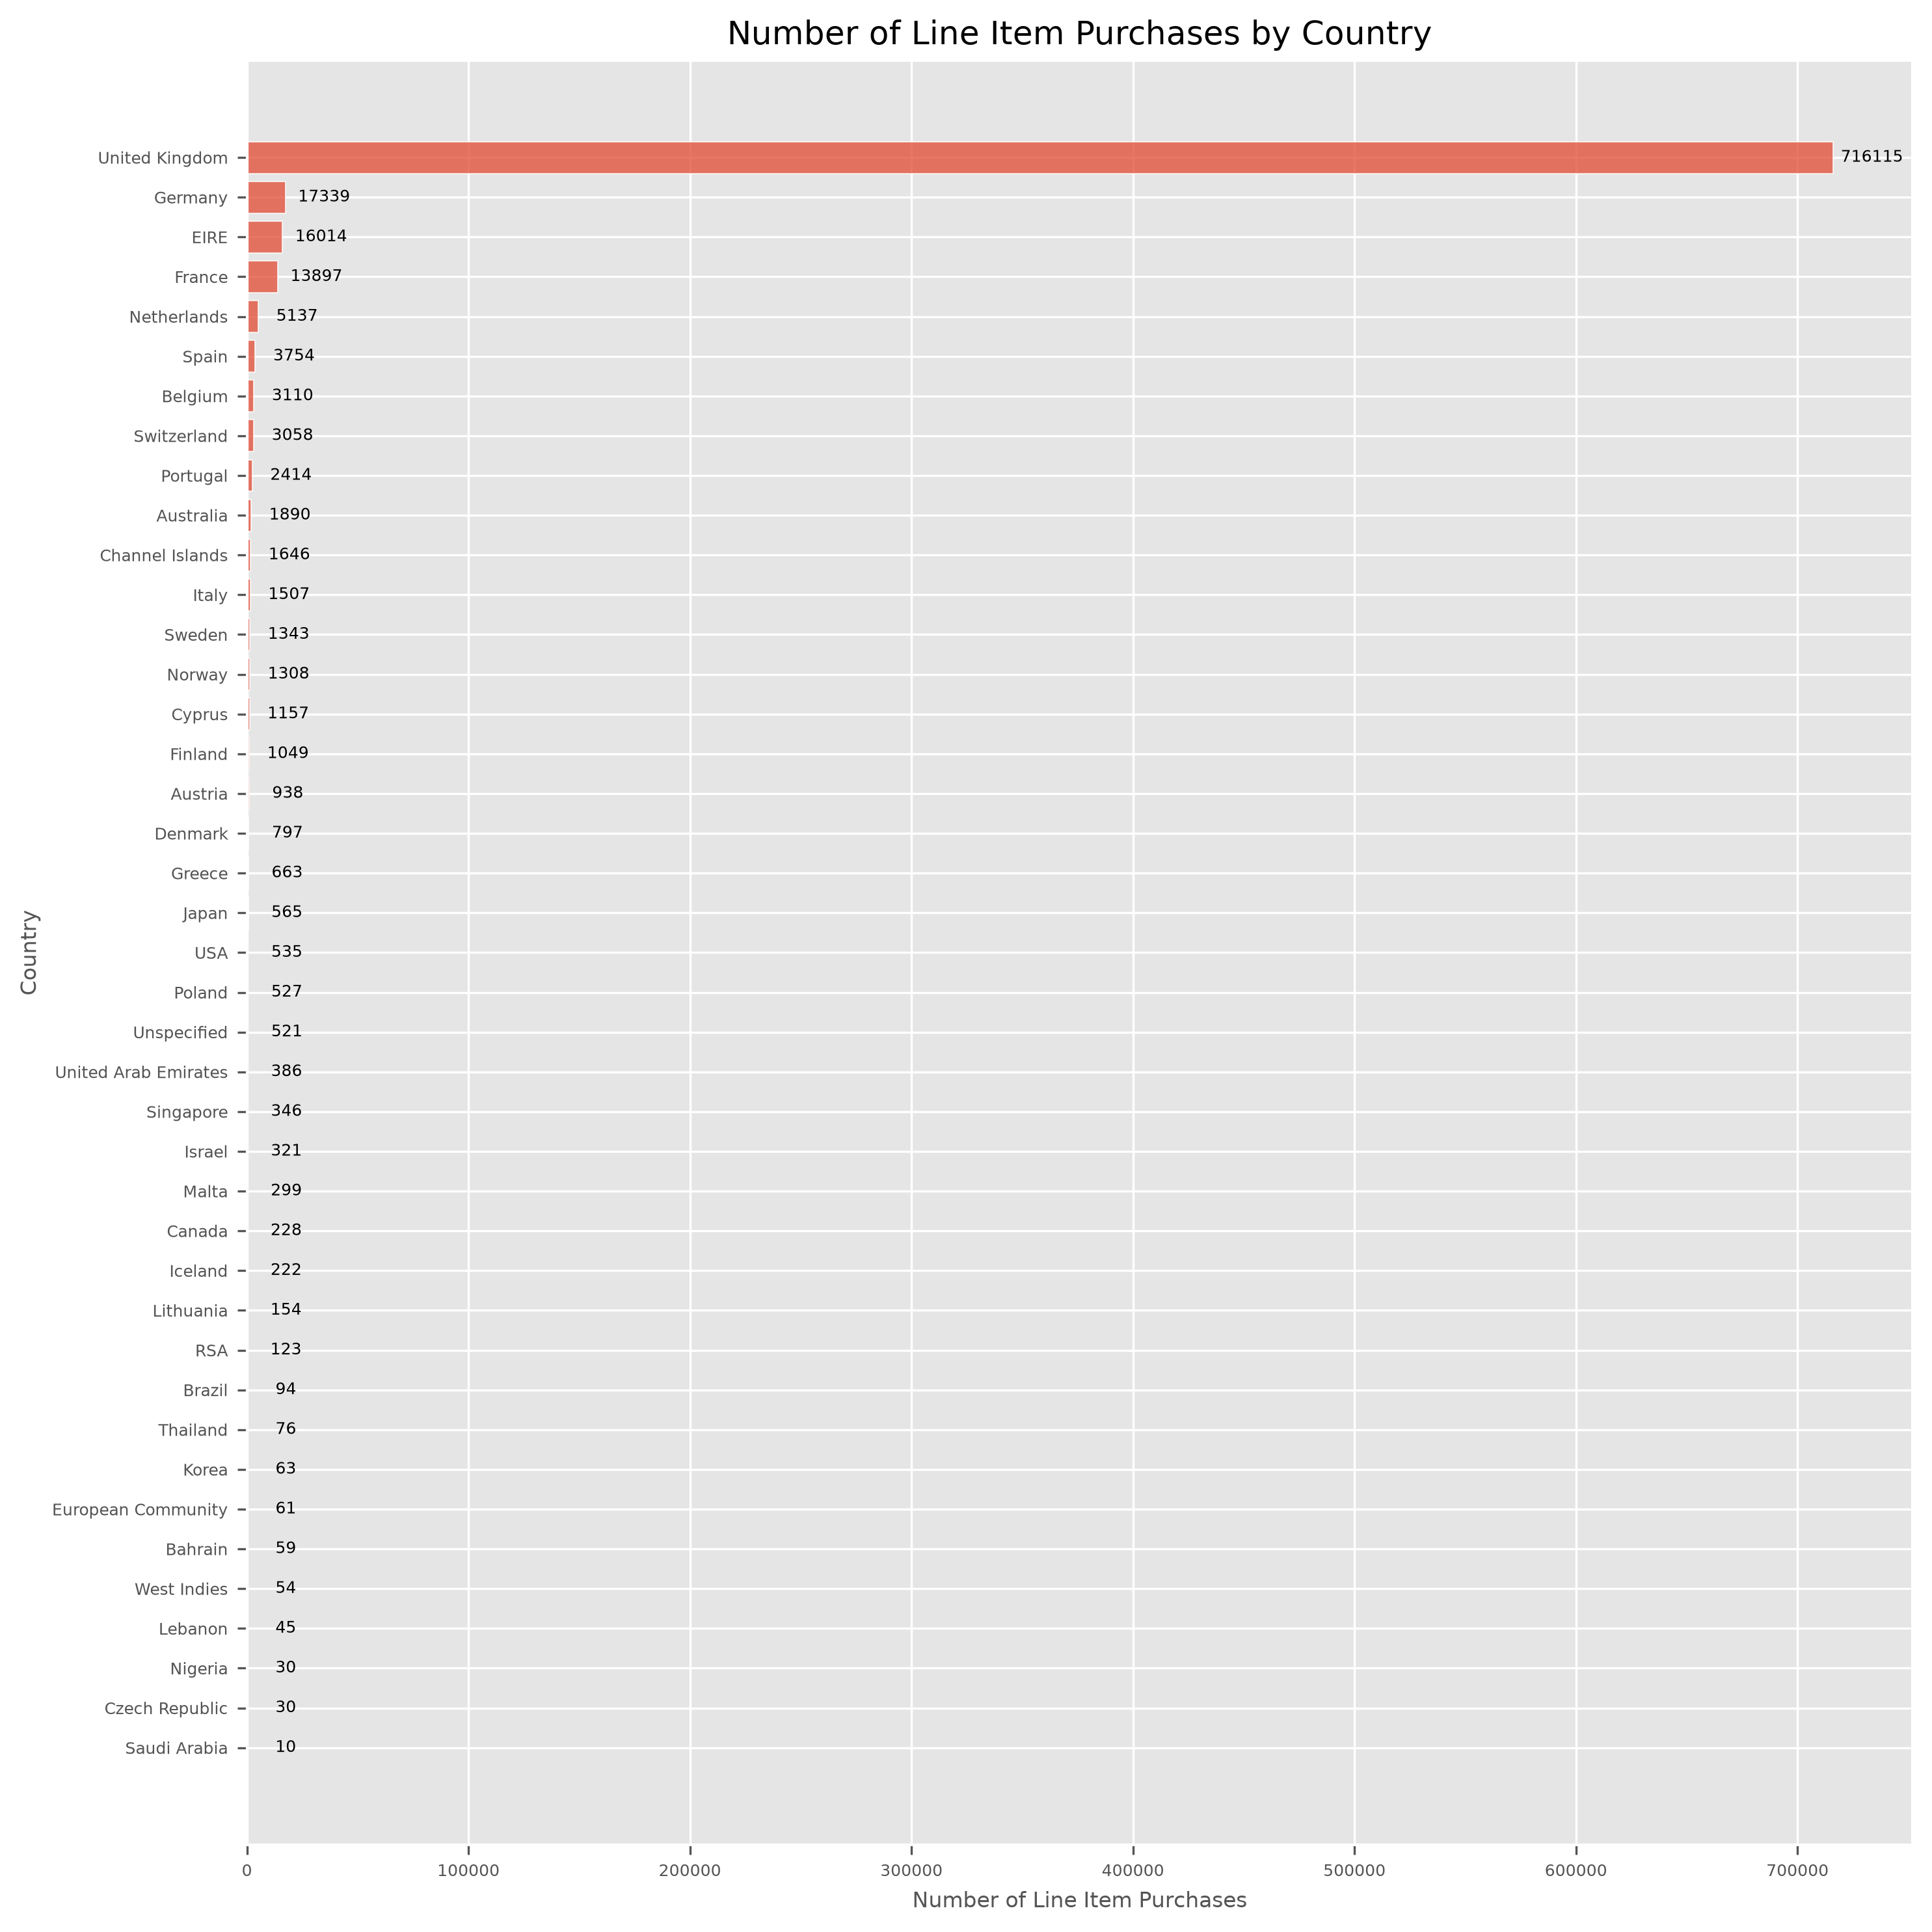

In [20]:
country = df_identified["country"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 10), dpi=300)

ax.barh(
    country.index, 
    country.values, 
    alpha=0.75, 
    edgecolor="#FFFFFF"
)
ax.set_xlabel("Number of Line Item Purchases", fontsize=AXIS_LABELS)
ax.set_ylabel("Country", fontsize=AXIS_LABELS)
ax.set_title("Number of Line Item Purchases by Country", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)

for index, count in enumerate(country.values):
    ax.text(count + 17500, index, count, ha="center", va="center", fontsize=TICKS)

fig.tight_layout()

In [21]:
country[~country.index.isin(["United Kingdom"])].describe()

count       40.000000
mean      2044.250000
std       4134.404461
min         10.000000
25%        115.750000
50%        531.000000
75%       1541.750000
max      17339.000000
Name: count, dtype: float64

Total number of customers in bar chart: 5955


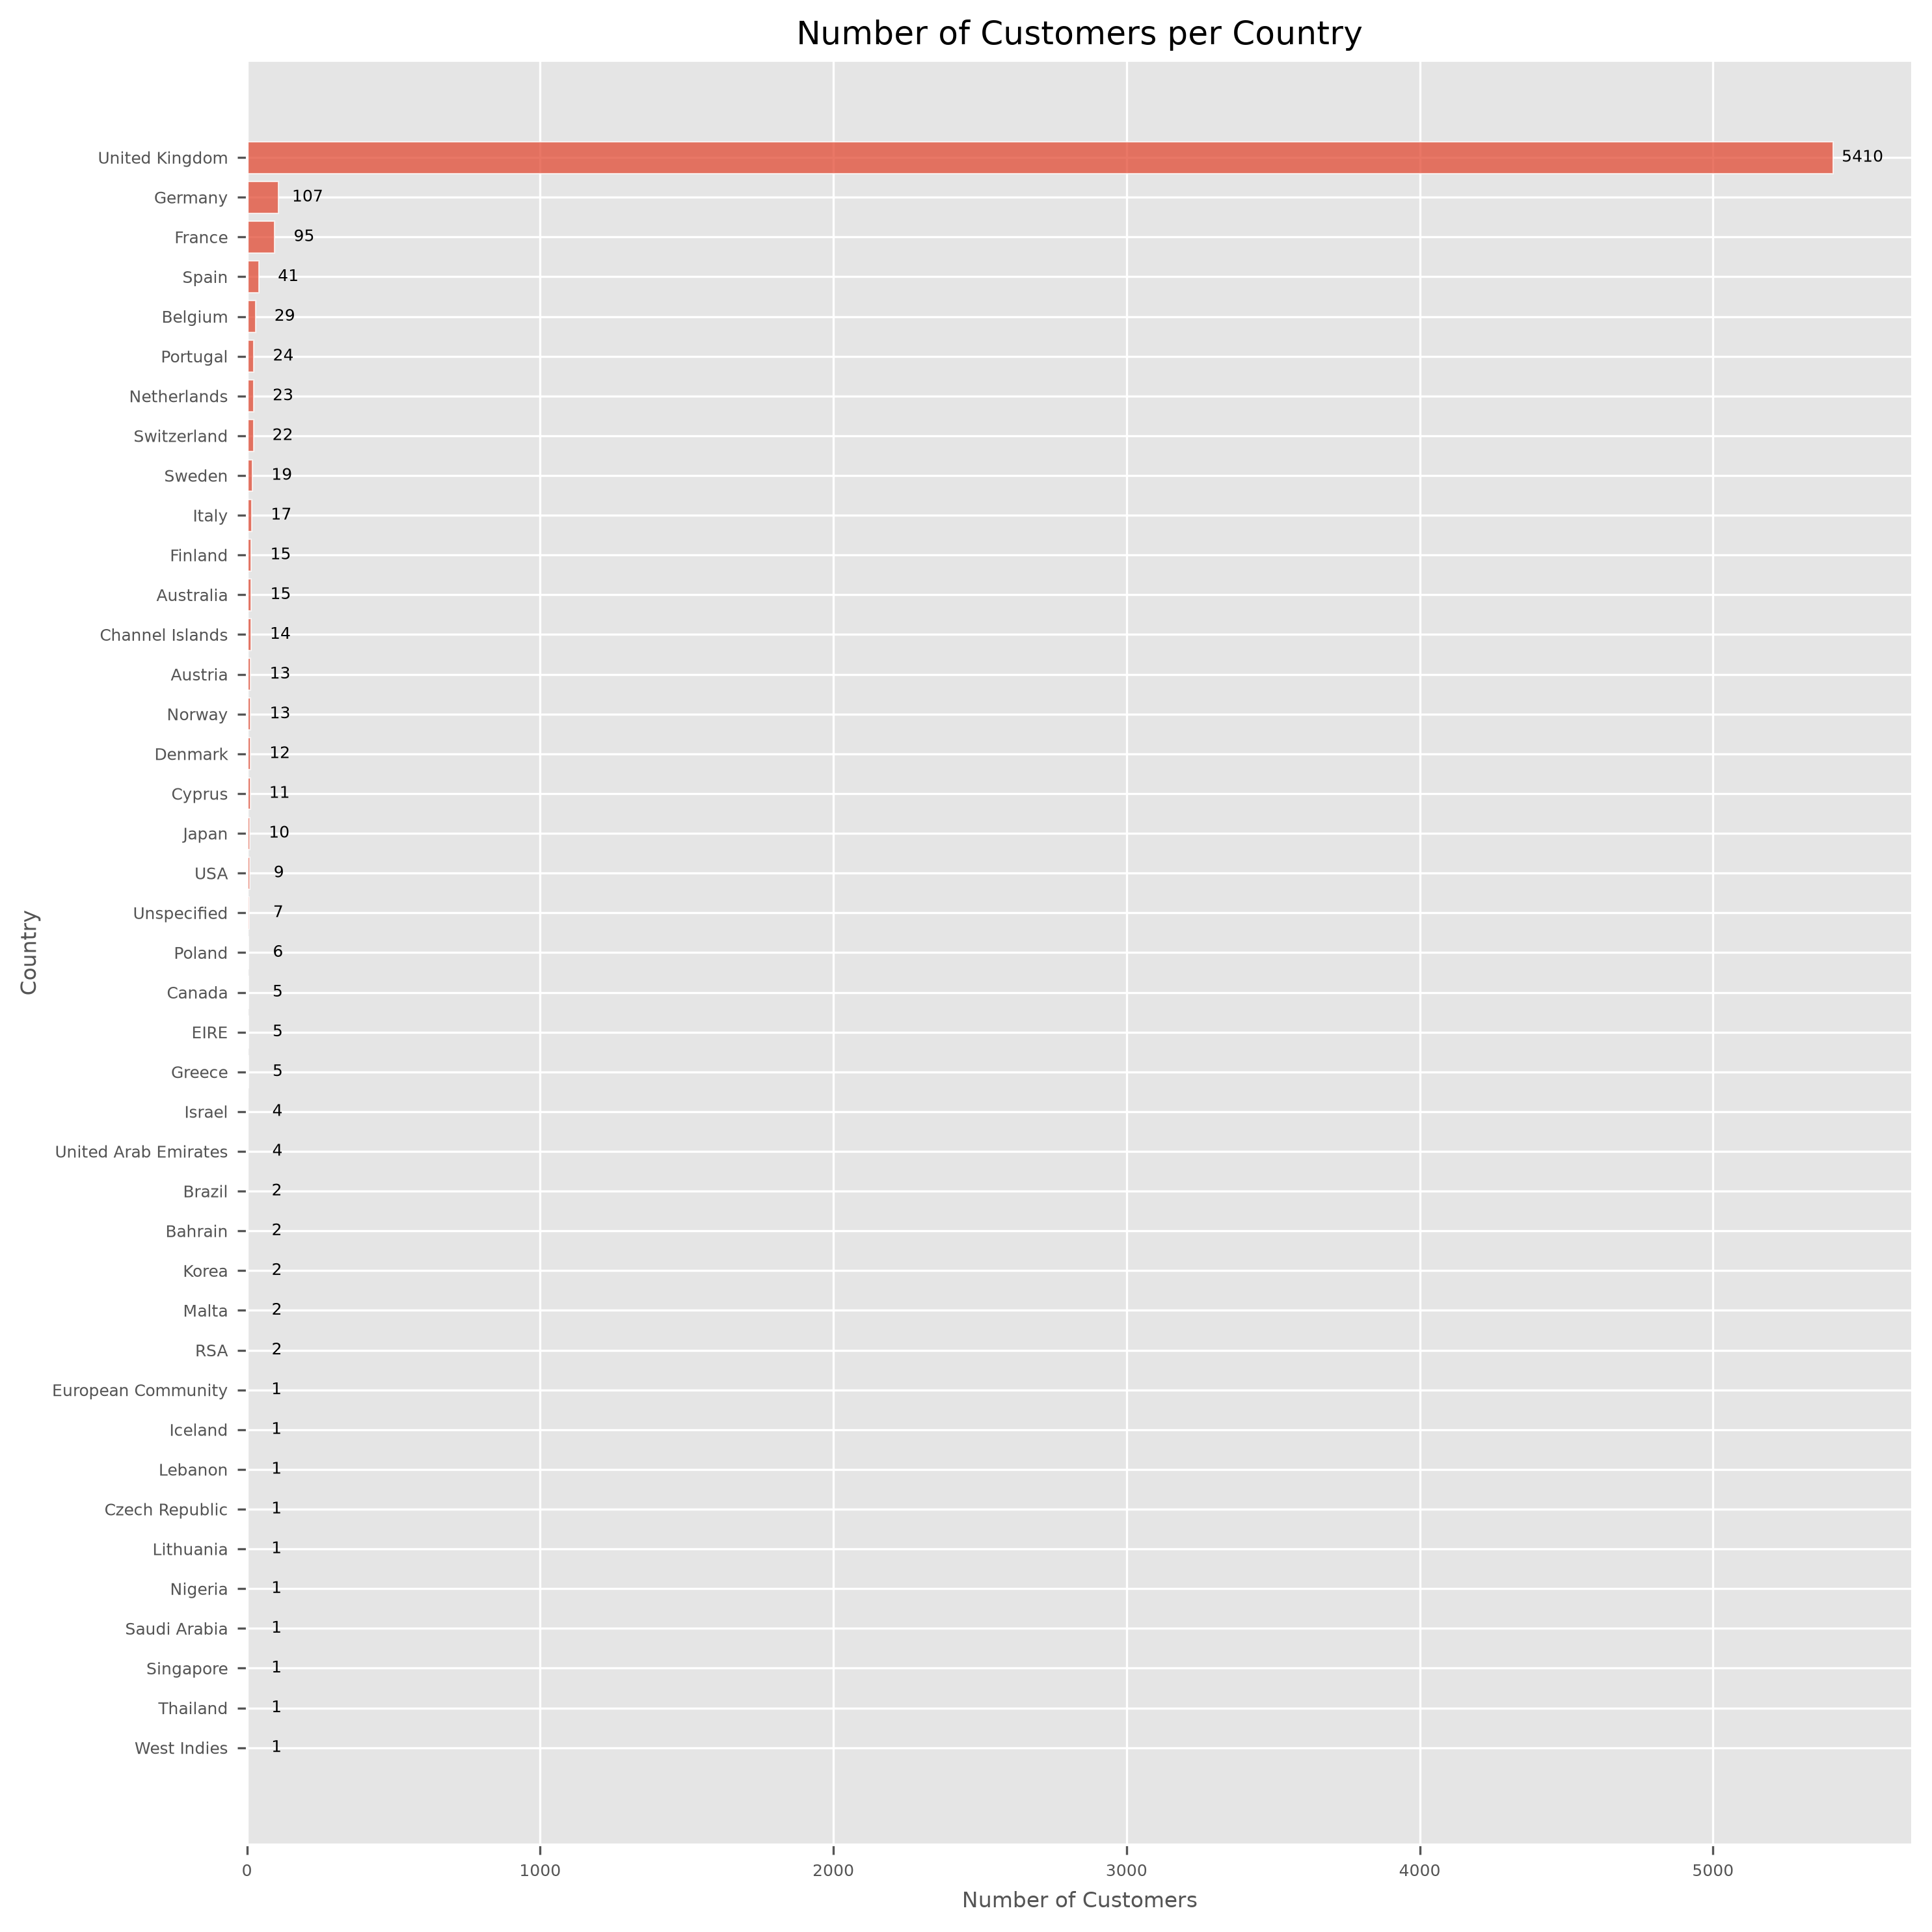

In [22]:
customers_per_country = df_identified.groupby("country")["customer_id"].nunique().sort_values(ascending=True)
print(f"Total number of customers in bar chart: {customers_per_country.values.sum()}")

fig, ax = plt.subplots(figsize=(10, 10), dpi=300)

ax.barh(
    customers_per_country.index, 
    customers_per_country.values, 
    alpha=0.75, 
    edgecolor="#FFFFFF"
)
ax.set_xlabel("Number of Customers", fontsize=AXIS_LABELS)
ax.set_ylabel("Country", fontsize=AXIS_LABELS)
ax.set_title("Number of Customers per Country", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)

for index, count in enumerate(customers_per_country.values):
    ax.text(count + 100, index, count, ha="center", va="center", fontsize=TICKS)

fig.tight_layout()

In [23]:
customers_per_country[~customers_per_country.index.isin(["United Kingdom"])].describe()

count     40.000000
mean      13.625000
std       22.338523
min        1.000000
25%        1.750000
50%        5.500000
75%       15.000000
max      107.000000
Name: customer_id, dtype: float64

In [24]:
country_count_by_id = df_identified.groupby("customer_id")["country"].nunique()

multi_country_customers = list(country_count_by_id[country_count_by_id > 1].index)
print(f"Number of customers with transactions from multiple countries: {len(multi_country_customers)}")

df_identified[
    df_identified["customer_id"].isin(multi_country_customers)
].groupby("customer_id")["country"].agg(set)

Number of customers with transactions from multiple countries: 13


customer_id
12370.0           {Cyprus, Austria}
12394.0          {Denmark, Belgium}
12413.0             {Spain, France}
12417.0            {Spain, Belgium}
12422.0    {Switzerland, Australia}
12423.0          {Denmark, Belgium}
12429.0          {Denmark, Austria}
12431.0        {Belgium, Australia}
12449.0          {Denmark, Belgium}
12455.0             {Cyprus, Spain}
12457.0       {Cyprus, Switzerland}
12652.0           {France, Germany}
12745.0      {EIRE, United Kingdom}
Name: country, dtype: object

In [25]:
purchase_qty_trends_by_id = df_identified.groupby("customer_id").agg(
    {"quantity": ["mean", "min", "median", "max", "count"]}
).sort_values(by=("quantity", "mean"), ascending=True)

purchase_qty_trends_by_id

quantity                             
                     mean    min   median    max count
customer_id                                           
13528.0        -16.000000    -16    -16.0    -16     1
15997.0        -12.000000    -12    -12.0    -12     1
14337.0        -10.916667    -60     -6.0     -3    36
13091.0         -8.893443   -120    -12.0    120   122
14864.0         -8.500000    -12     -8.5     -5     2
...                   ...    ...      ...    ...   ...
13687.0       1937.044444     72   1200.0   7128    45
17940.0       2076.634146     -1    432.0  10000    41
16308.0       2285.714286   1000   2000.0   3000     7
13902.0       3255.074627  -2504   2504.0  19152    67
13256.0      12540.000000  12540  12540.0  12540     1

[5942 rows x 5 columns]

In [26]:
most_freq_purchase_qty_by_id = df_identified.groupby("customer_id")["quantity"].agg(lambda x: x.mode().iloc[0])
most_freq_purchase_qty_by_id # Series can be used to identify wholesalers

customer_id
12346.0     1
12347.0    12
12348.0    24
12349.0    12
12350.0    12
           ..
18283.0     1
18284.0    12
18285.0     4
18286.0    12
18287.0    12
Name: quantity, Length: 5942, dtype: int64

In [27]:
purchase_qty_trends_by_country = df_identified.groupby("country").agg(
    {"quantity": ["mean", "min", "median", "max"]}
).sort_values(by=("quantity", "mean"), ascending=True)

purchase_qty_trends_by_country

quantity                     
                            mean    min median    max
country                                              
Nigeria                 3.433333      1    1.0     25
Brazil                  5.797872      1    3.0     25
USA                     6.915888    -36    6.0    288
West Indies             7.314815      1    4.5     36
Saudi Arabia            7.500000     -5    9.0     12
RSA                     7.666667      1    8.0     24
European Community      8.147541     -2    6.0     24
Malta                   8.331104     -4    6.0    144
Lebanon                 8.577778      2    8.0     24
Cyprus                  9.206569   -200    6.0    288
Korea                   9.492063    -48    6.0     48
Unspecified             9.786948    -12    6.0    120
Italy                  10.034506    -12    6.0    300
Poland                 10.444023    -36   10.0     72
Belgium                11.124759    -30   10.0    272
Portugal               11.214582    -60   10.0    120
United Kingdom         11.442740 -80995    4.0  80995
Greece                 11.624434    -11   12.0     96
Spain                  11.898508   -576    6.0    576
Austria                12.053305    -48   10.0    288
Channel Islands        12.385784   -300    8.0    407
Germany                12.792895   -288   10.0    600
Bahrain                12.796610      2    8.0     96
France                 12.949486  -7128   10.0   7128
Iceland                13.364865      2   12.0    240
Finland                13.648236    -27   10.0    144
United Arab Emirates   14.821244    -72   12.0    288
Lithuania              14.974026      4   12.0     48
Israel                 15.947040    -32   12.0    100
Canada                 16.039474      1   12.0    504
Switzerland            16.913342   -120   12.0    288
Norway                 17.987768    -12   12.0    240
EIRE                   19.340390   -400   10.0   1440
Czech Republic         19.733333    -24   24.0     72
Singapore              20.193642     -1   12.0    288
Thailand               33.578947      1    6.0    288
Japan                  53.341593   -624   20.0   2040
Australia              54.695767   -120   16.0   1152
Sweden                 65.316456   -240   12.0   1440
Netherlands            74.333852   -480   48.0   2400
Denmark               294.559598  -2504   16.0  19152

In [28]:
most_freq_purchase_qty_by_country = df_identified.groupby("country")["quantity"].agg(lambda x: x.mode().iloc[0]) 
most_freq_purchase_qty_by_country # Series can be used to identify countries with more wholesalers (answer is inconclusive)

country
Australia               12
Austria                 12
Bahrain                 12
Belgium                 12
Brazil                   1
Canada                  12
Channel Islands         12
Cyprus                  12
Czech Republic          24
Denmark                 12
EIRE                    12
European Community       6
Finland                 12
France                  12
Germany                 12
Greece                  12
Iceland                 12
Israel                  24
Italy                   12
Japan                    1
Korea                    6
Lebanon                 12
Lithuania               12
Malta                   12
Netherlands             12
Nigeria                  1
Norway                  12
Poland                  12
Portugal                12
RSA                     12
Saudi Arabia            12
Singapore               12
Spain                   12
Sweden                  12
Switzerland             12
Thailand                 6
USA                 

### **Transaction Data**

In [29]:
df_identified["invoice"].value_counts()

invoice
576339     542
579196     533
580727     529
578270     442
573576     435
          ... 
581487       1
581491       1
C581499      1
581566       1
C581568      1
Name: count, Length: 44876, dtype: int64

In [30]:
invoices = list(df_identified["invoice"].value_counts().index)
str_invoices = {invoice for invoice in invoices if isinstance(invoice, str)}
print(f"Number of unique invoices (str): {len(str_invoices)}")

# Verification that the invoice data only contains integers and strings starting with "C"
letter_headers = {invoice[0] for invoice in str_invoices}
print("Unique letter headers:")
for index, item in enumerate(letter_headers, start=1):
    print(f"{index}: {item}")

Number of unique invoices (str): 7901
Unique letter headers:
1: C


In [31]:
int_invoices = {invoice for invoice in invoices if isinstance(invoice, int)}

pd.DataFrame({
    "completed": [len(int_invoices)],
    "cancelled": [len(str_invoices)],
}, index=["Number of transactions (unique invoices)"])

,completed,cancelled
Number of transactions (unique invoices),36975,7901


In [32]:
print(f"First transaction: {df_identified["invoice_date"].min()}")
print(f"Last transaction: {df_identified["invoice_date"].max()}")

First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00


In [33]:
df_identified["invoice_date"].max() - df_identified["invoice_date"].min()

Timedelta('738 days 05:05:00')

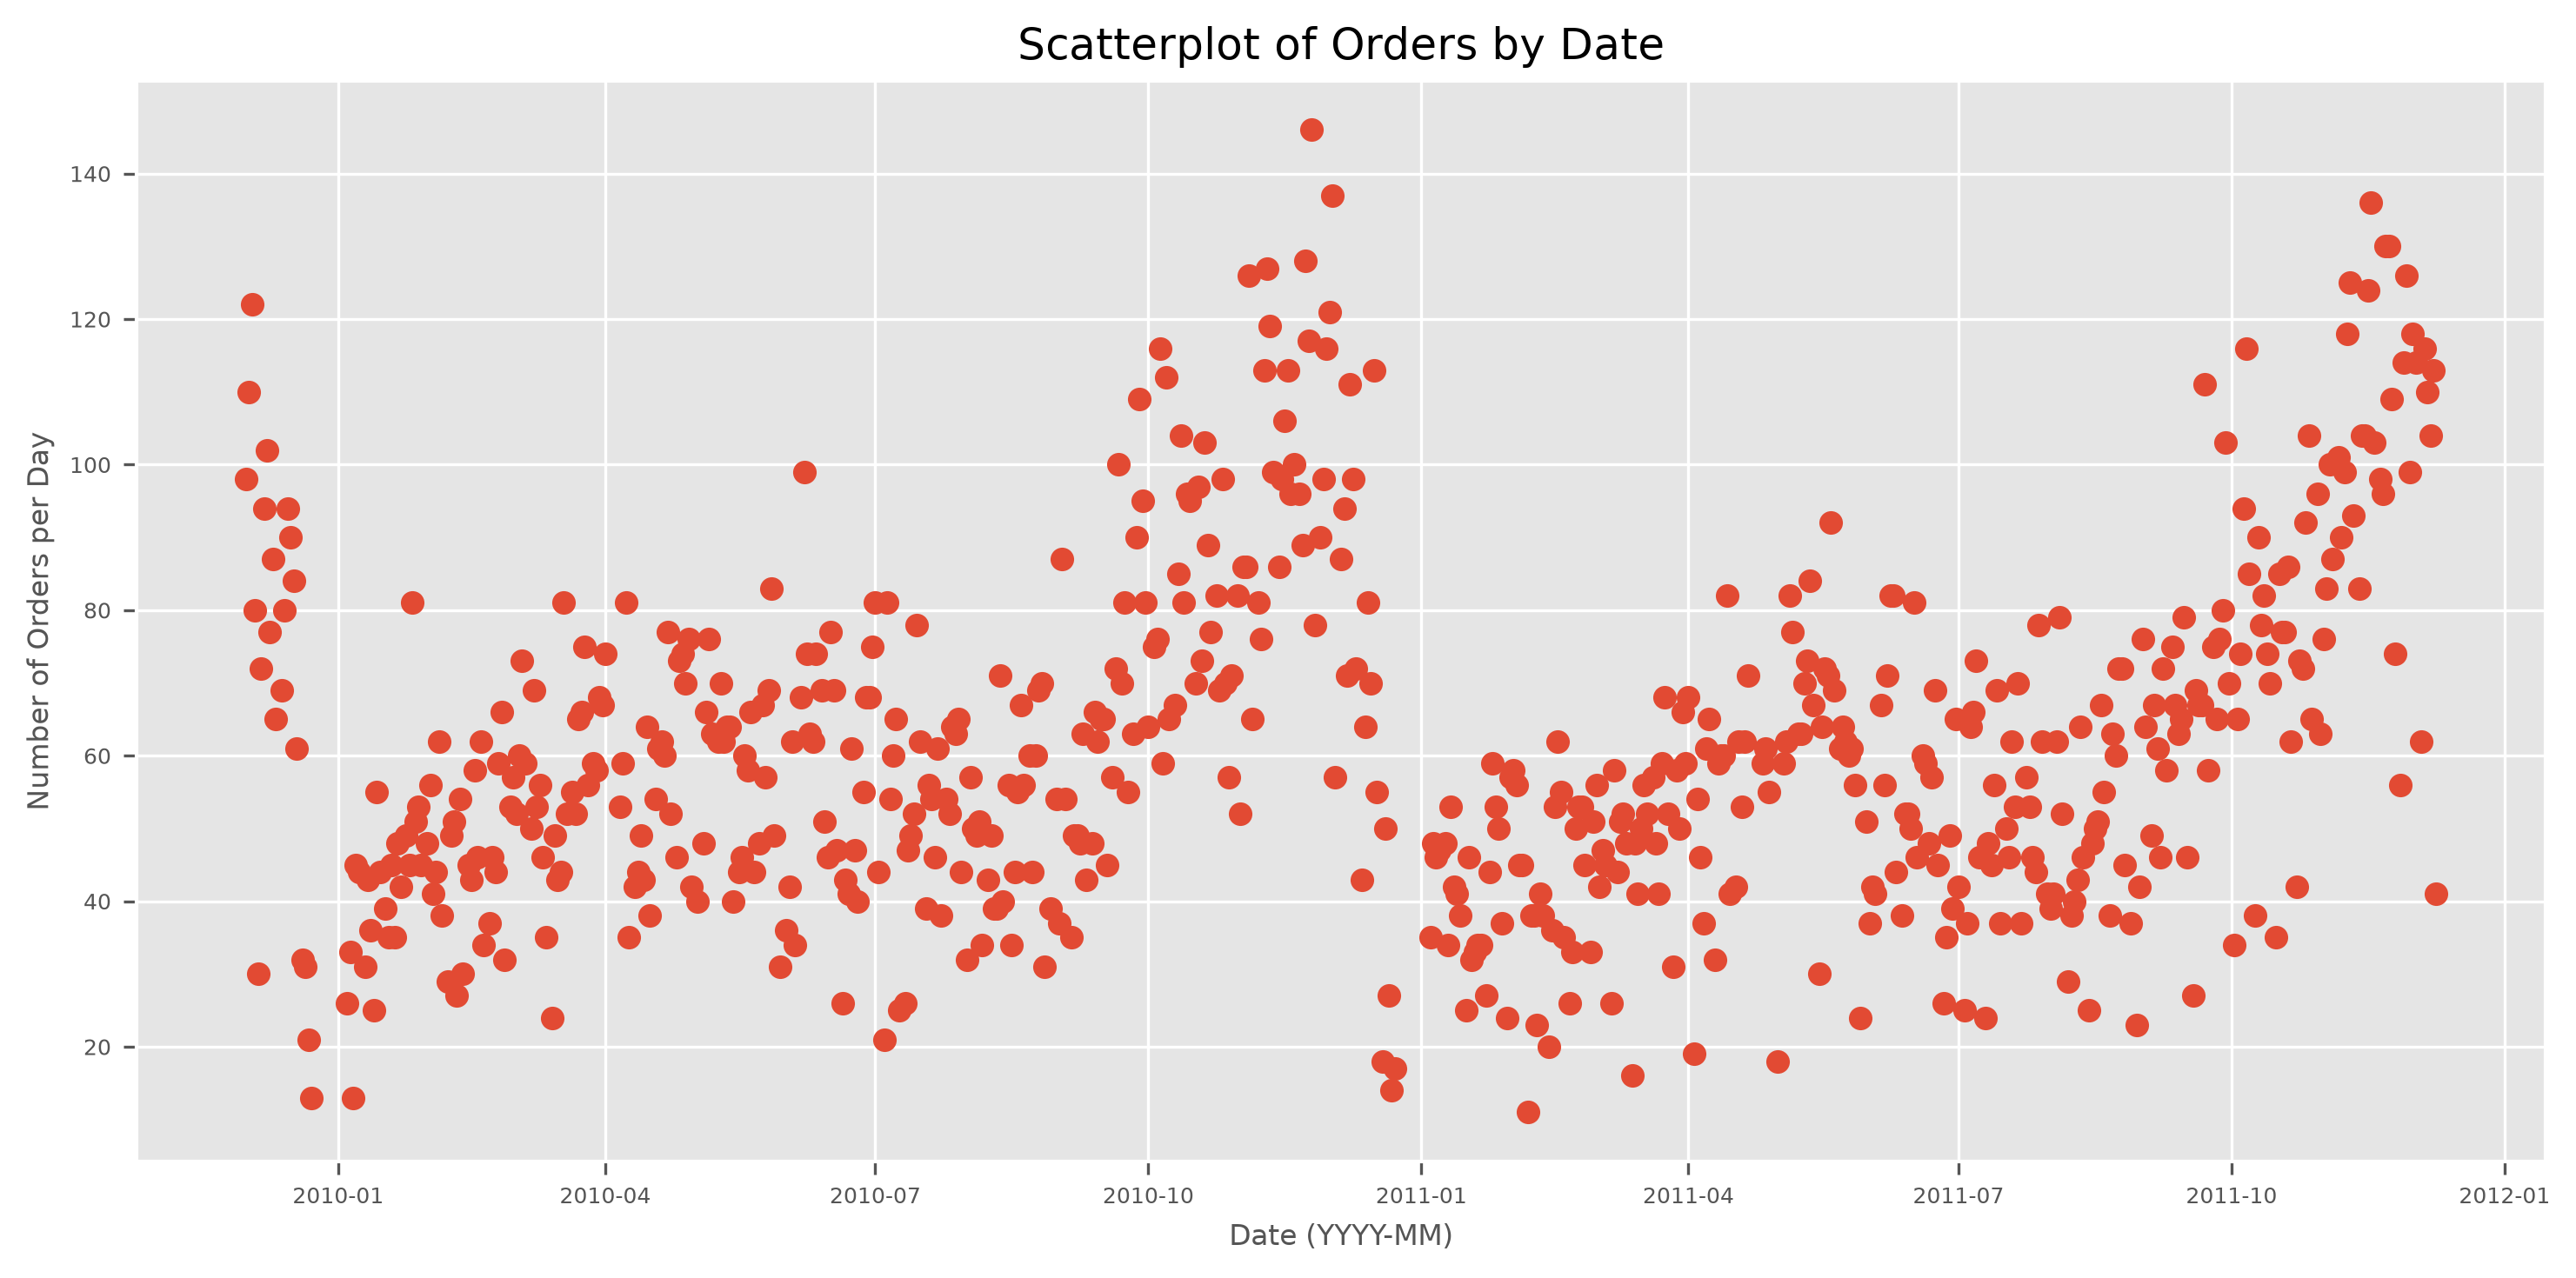

In [34]:
orders_by_date = df_identified[~df_identified["invoice"].isin(str_invoices)].groupby(
    ["customer_id", "invoice"]
)["invoice_date"].min().reset_index()

orders_by_date = orders_by_date["invoice_date"].dt.normalize().value_counts()

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

ax.scatter(orders_by_date.index, orders_by_date.values)
ax.set_xlabel("Date (YYYY-MM)", fontsize=AXIS_LABELS)
ax.set_ylabel("Number of Orders per Day", fontsize=AXIS_LABELS)
ax.set_title("Scatterplot of Orders by Date", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)

fig.tight_layout()

### **Product Data**

In [35]:
df_identified["stock_code"].value_counts()

stock_code
85123A    5156
22423     3678
85099B    3380
84879     2709
20725     2686
          ... 
90141D       1
84387A       1
20678        1
23664        1
23449        1
Name: count, Length: 4646, dtype: int64

In [36]:
df_identified["stock_code"].describe()

count     797885
unique      4646
top       85123A
freq        5156
Name: stock_code, dtype: object

In [37]:
stock_codes = list(df_identified["stock_code"].value_counts().index)
str_stock_codes = {stock_code for stock_code in stock_codes if isinstance(stock_code, str)}
print(f"Number of unique stock codes (str): {len(str_stock_codes)}")

df_identified[df_identified["stock_code"].isin(str_stock_codes)].head(10)

Number of unique stock codes (str): 1315


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
23,489436,35004B,SET OF 3 BLACK FLYING DUCKS,12,2009-12-01 09:06:00,4.65,13078.0,United Kingdom
29,489436,84596L,BISCUITS SMALL BOWL LIGHT BLUE,8,2009-12-01 09:06:00,1.25,13078.0,United Kingdom
28,489436,84596F,SMALL MARSHMALLOWS PINK BOWL,8,2009-12-01 09:06:00,1.25,13078.0,United Kingdom
12,489436,48173C,DOOR MAT BLACK FLOCK,10,2009-12-01 09:06:00,5.95,13078.0,United Kingdom
46,489437,84970S,HANGING HEART ZINC T-LIGHT HOLDER,12,2009-12-01 09:08:00,0.85,15362.0,United Kingdom
42,489437,84507B,STRIPES DESIGN MONKEY DOLL,6,2009-12-01 09:08:00,2.55,15362.0,United Kingdom
63,489438,84032A,CHARLIE+LOLA PINK HOT WATER BOTTLE,60,2009-12-01 09:24:00,1.90,18102.0,United Kingdom
70,489438,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,60,2009-12-01 09:24:00,2.40,18102.0,United Kingdom


In [38]:
# Checking lowercase letters for numerical stock codes in str_stock_codes
len({stock_code for stock_code in str_stock_codes if re.search(r"^[0-9]{5}[a-z]+$", stock_code)})

0

In [39]:
# Checking uppercase letters for numerical stock codes in str_stock_codes
len({stock_code for stock_code in str_stock_codes if re.search(r"^[0-9]{5}[A-Z]+$", stock_code)})

1302

In [40]:
# Checking for str stock codes that do not match the regex pattern
len({stock_code for stock_code in str_stock_codes if not re.search(r"^[0-9]{5}[A-Z]+$", stock_code)})

13

In [41]:
non_numerical_stock_codes = {stock_code for stock_code in str_stock_codes if not re.search(r"^[0-9]{5}[A-Z]+$", stock_code)}

pd.DataFrame({
    "Numerical": [len({stock_code for stock_code in stock_codes if isinstance(stock_code, int)})],
    "Numerical (r'^[0-9]{5}[A-Z]+$' Format)": [(len(str_stock_codes) - len(non_numerical_stock_codes))],
    "Non-Numerical": [len(non_numerical_stock_codes)]
}, index=["stock_codes"])

,Numerical,Numerical (r'^[0-9]{5}[A-Z]+$' Format),Non-Numerical
stock_codes,3331,1302,13


In [42]:
df_identified["stock_code"].value_counts().loc[list(non_numerical_stock_codes)]

stock_code
CRUK              16
M               1085
DOT               16
BANK CHARGES      37
TEST002            1
C2               254
ADJUST            61
SP1002             2
D                170
ADJUST2            3
POST            1983
TEST001           15
PADS              19
Name: count, dtype: int64

In [43]:
df_non_numerical_stock_codes = df_identified[df_identified["stock_code"].isin(non_numerical_stock_codes)]
df_non_numerical_stock_codes[["stock_code", "description"]].drop_duplicates()

,stock_code,description
89,POST,POSTAGE
716,D,Discount
2121,M,Manual
6725,C2,CARRIAGE
14036,BANK CHARGES,Bank Charges
21447,TEST001,This is a test product.
28504,TEST002,This is a test product.
42295,PADS,PADS TO MATCH ALL CUSHIONS
48957,ADJUST,Adjustment by john on 26/01/2010 16
49036,ADJUST,Adjustment by john on 26/01/2010 17


In [44]:
transactions_non_numerical_stock_code = df_identified["stock_code"].value_counts().loc[
    list(non_numerical_stock_codes)
].values.sum()
print(f"Number of transactions with non-numerical stock codes: {transactions_non_numerical_stock_code}")

Number of transactions with non-numerical stock codes: 3662


**Note:** As product descriptions are tied to (and therefore represented by) stock codes, no feature analysis will be conducted. The column will be dropped prior to any supervised machine learning.

In [45]:
df_identified["price"].describe()

count    797885.000000
mean          3.702732
std          71.392549
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max       38970.000000
Name: price, dtype: float64

In [46]:
df_identified[df_identified["price"] == 0]

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
3691,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom
4814,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom
12801,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom
14356,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
14355,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.0,14108.0,United Kingdom
...,...,...,...,...,...,...,...,...
752851,577129,22464,HANGING METAL HEART LANTERN,4,2011-11-17 19:52:00,0.0,15602.0,United Kingdom
753225,577168,M,Manual,1,2011-11-18 10:42:00,0.0,12603.0,Germany
754280,577314,23407,SET OF 2 TRAYS HOME SWEET HOME,2,2011-11-18 13:23:00,0.0,12444.0,Norway
758708,577696,M,Manual,1,2011-11-21 11:57:00,0.0,16406.0,United Kingdom


In [47]:
# Price distribution of products with numerical stock codes
df_identified[~df_identified["stock_code"].isin(non_numerical_stock_codes)][["price", "stock_code"]].describe()

,price
count,794223.000000
mean,2.971190
std,4.474925
min,0.000000
25%,1.250000
50%,1.950000
75%,3.750000
max,649.500000


In [48]:
# Price distribution of products with non-numerical stock codes
df_identified[df_identified["stock_code"].isin(non_numerical_stock_codes)][["price", "stock_code"]].describe()

,price
count,3662.000000
mean,162.361204
std,1039.800788
min,0.000000
25%,15.000000
50%,18.000000
75%,40.000000
max,38970.000000


### **Summary of Findings from Initial Feature Analysis**

**Customer Data**

- There are 5,942 customers in this dataset. 4,481 are returning customers. 5,410 are from the UK. The rest are distributed across 40 other countries (averaging 13 customers per country). There are 13 customers who have made orders from multiple countries. Only 1 of these are from the UK. 

- Given the small number of multi-country customers, their inclusion in the processed dataset could be an unwanted identifier signal which may result in overfitting. Similarly, due to the small number of customers in each of the 40 non-UK countries, listing the exact country itself may also cause overfitting. To resolve these issues, only the modal country for each customer should be listed, with all non-UK customers grouped into an "infrequent" bucket using the Scikit-Learn OneHotEncoder.

- In alignment with the customer demographic, most of the line item purchases in the dataset (716,115) were also from the UK. The remaining countries had an average of 2,044 purchases each. 

- Customer purchase quantity trends varied significantly at the customer_id level. However, no country presented noticeable wholesale purchasing behaviour. The modal purchase quantity per line item per customer at the national level was 12 or less for all the countries listed (except for the Czech Republic, which had 24).

**Transaction Data**

- There are 36,975 completed transactions and 7,901 cancellations in the dataset.

- The first and last transactions in the dataset were completed on 2009-12-01 at 07:45:00 and 2011-12-09 at 12:50:00 respectively. The dataset covers a total of 738 days.

- In each year, most of the transactions take place between October and January. This clustering around the holiday season is expected, given that the dataset is from a retail store selling gift-ware.

**Product Data**

- There are 4646 unique stock codes (and by extension, products) in the dataset. 13 are non-numerical stock codes. Based on their accompanying descriptions, most of the non-numerical stock codes were not representative of actual products. The exceptions were "SP1002" (2 purchases) and "PADS" (19 purchases).

- Most items were sold at low prices (mean price was £3.70). However, outliers in the price distribution are significantly higher. The highest transaction price recorded was £38,970.00.

- There are items sold at £0.00. They should remain in the dataset as they correspond to actual transactions (likely free gifts) that reflect e-commerce activity.

- Bivariate analysis revealed that higher transaction prices strongly correlated with non-numerical stock codes. The mean price for numerical and non-numerical stock codes were £2.97 and £162.36 respectively. The highest prices from each group were £649.50 and £38,970.00 respectively. 

- As non-numerical stock codes are mostly not representative of actual products, all instances (apart from the exceptions) should be dropped from the dataframe prior to supervised machine learning. This will help avoid unnecessary skews in price, whilst also enabling the dataset to be more reflective of actual e-commerce activity.

## **RFM Analysis**

### **Dropping the Rows with Non-Numerical Stock Codes**

In [49]:
NON_PRODUCT = ["POST", "D", "M", "C2", "BANK CHARGES", "TEST001", "TEST002", "ADJUST", "ADJUST2", "DOT", "CRUK"]

df_identified["stock_code"] = df_identified["stock_code"].astype("string")
n_before = len(df_identified)
df_identified = df_identified[
    ~df_identified["stock_code"].isin(NON_PRODUCT)
].reset_index(drop=True)

print(f"Number of non-product rows dropped: {n_before - len(df_identified)}")

Number of non-product rows dropped: 3641


In [50]:
df_identified.info()

<class 'pandas.DataFrame'>
RangeIndex: 794244 entries, 0 to 794243
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   invoice       794244 non-null  object        
 1   stock_code    794244 non-null  string        
 2   description   794244 non-null  object        
 3   quantity      794244 non-null  int64         
 4   invoice_date  794244 non-null  datetime64[us]
 5   price         794244 non-null  float64       
 6   customer_id   794244 non-null  float64       
 7   country       794244 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(2), str(1), string(1)
memory usage: 62.6+ MB


In [51]:
df_identified["customer_id"].nunique() # Important note: several one-time customers had non-numerical stock code transactions only.

5876

### **Recency**

#### **Selecting a Churn Horizon**

Given that this dataset is for non-contractual e-commerce, there is no observable churn event. As such, the churn label must be defined. For this project, the label will be determined by customer inactivity. Any customer who fails to make another purchase within a specific number of days since their last purchase (the churn horizon) will be labelled as churned. 

The horizon drives the model's base rate. If set too low, less time is available for customers to make a purchase, which may result in them being prematurely labelled as churned. If set too high, genuine churns may be unintentionally labelled as active. Moreover, a high churn horizon value would also cost training data, as every observation window cutoff requires a full outcome window after it. Careful churn horizon value selection is therefore essential to effective non-contractual churn modelling.

Another business-specific note: **all customers will churn eventually**. Building a model using a high churn horizon value would limit its efficacy, as predictions that look a year ahead (or similar) offer limited actionable intervention opportunities. The horizon should create an outcome window that is short enough to act on, yet long enough to accurately predict churn.

In [52]:
orders_per_customer = df_identified[~df_identified["invoice"].isin(str_invoices)].groupby(
    ["customer_id", "invoice"]
)["invoice_date"].min().reset_index()

orders_per_customer["days_since_prev_order"] = orders_per_customer.groupby("customer_id")["invoice_date"].diff().dt.days
orders_per_customer["days_since_prev_order"] = orders_per_customer["days_since_prev_order"].dropna() # To remove the NaT values for each customer's first transaction
intervals = orders_per_customer["days_since_prev_order"]
mean_intervals = orders_per_customer.groupby("customer_id")["days_since_prev_order"].mean()
median_intervals = orders_per_customer.groupby("customer_id")["days_since_prev_order"].median()
max_intervals = orders_per_customer.groupby("customer_id")["days_since_prev_order"].max()

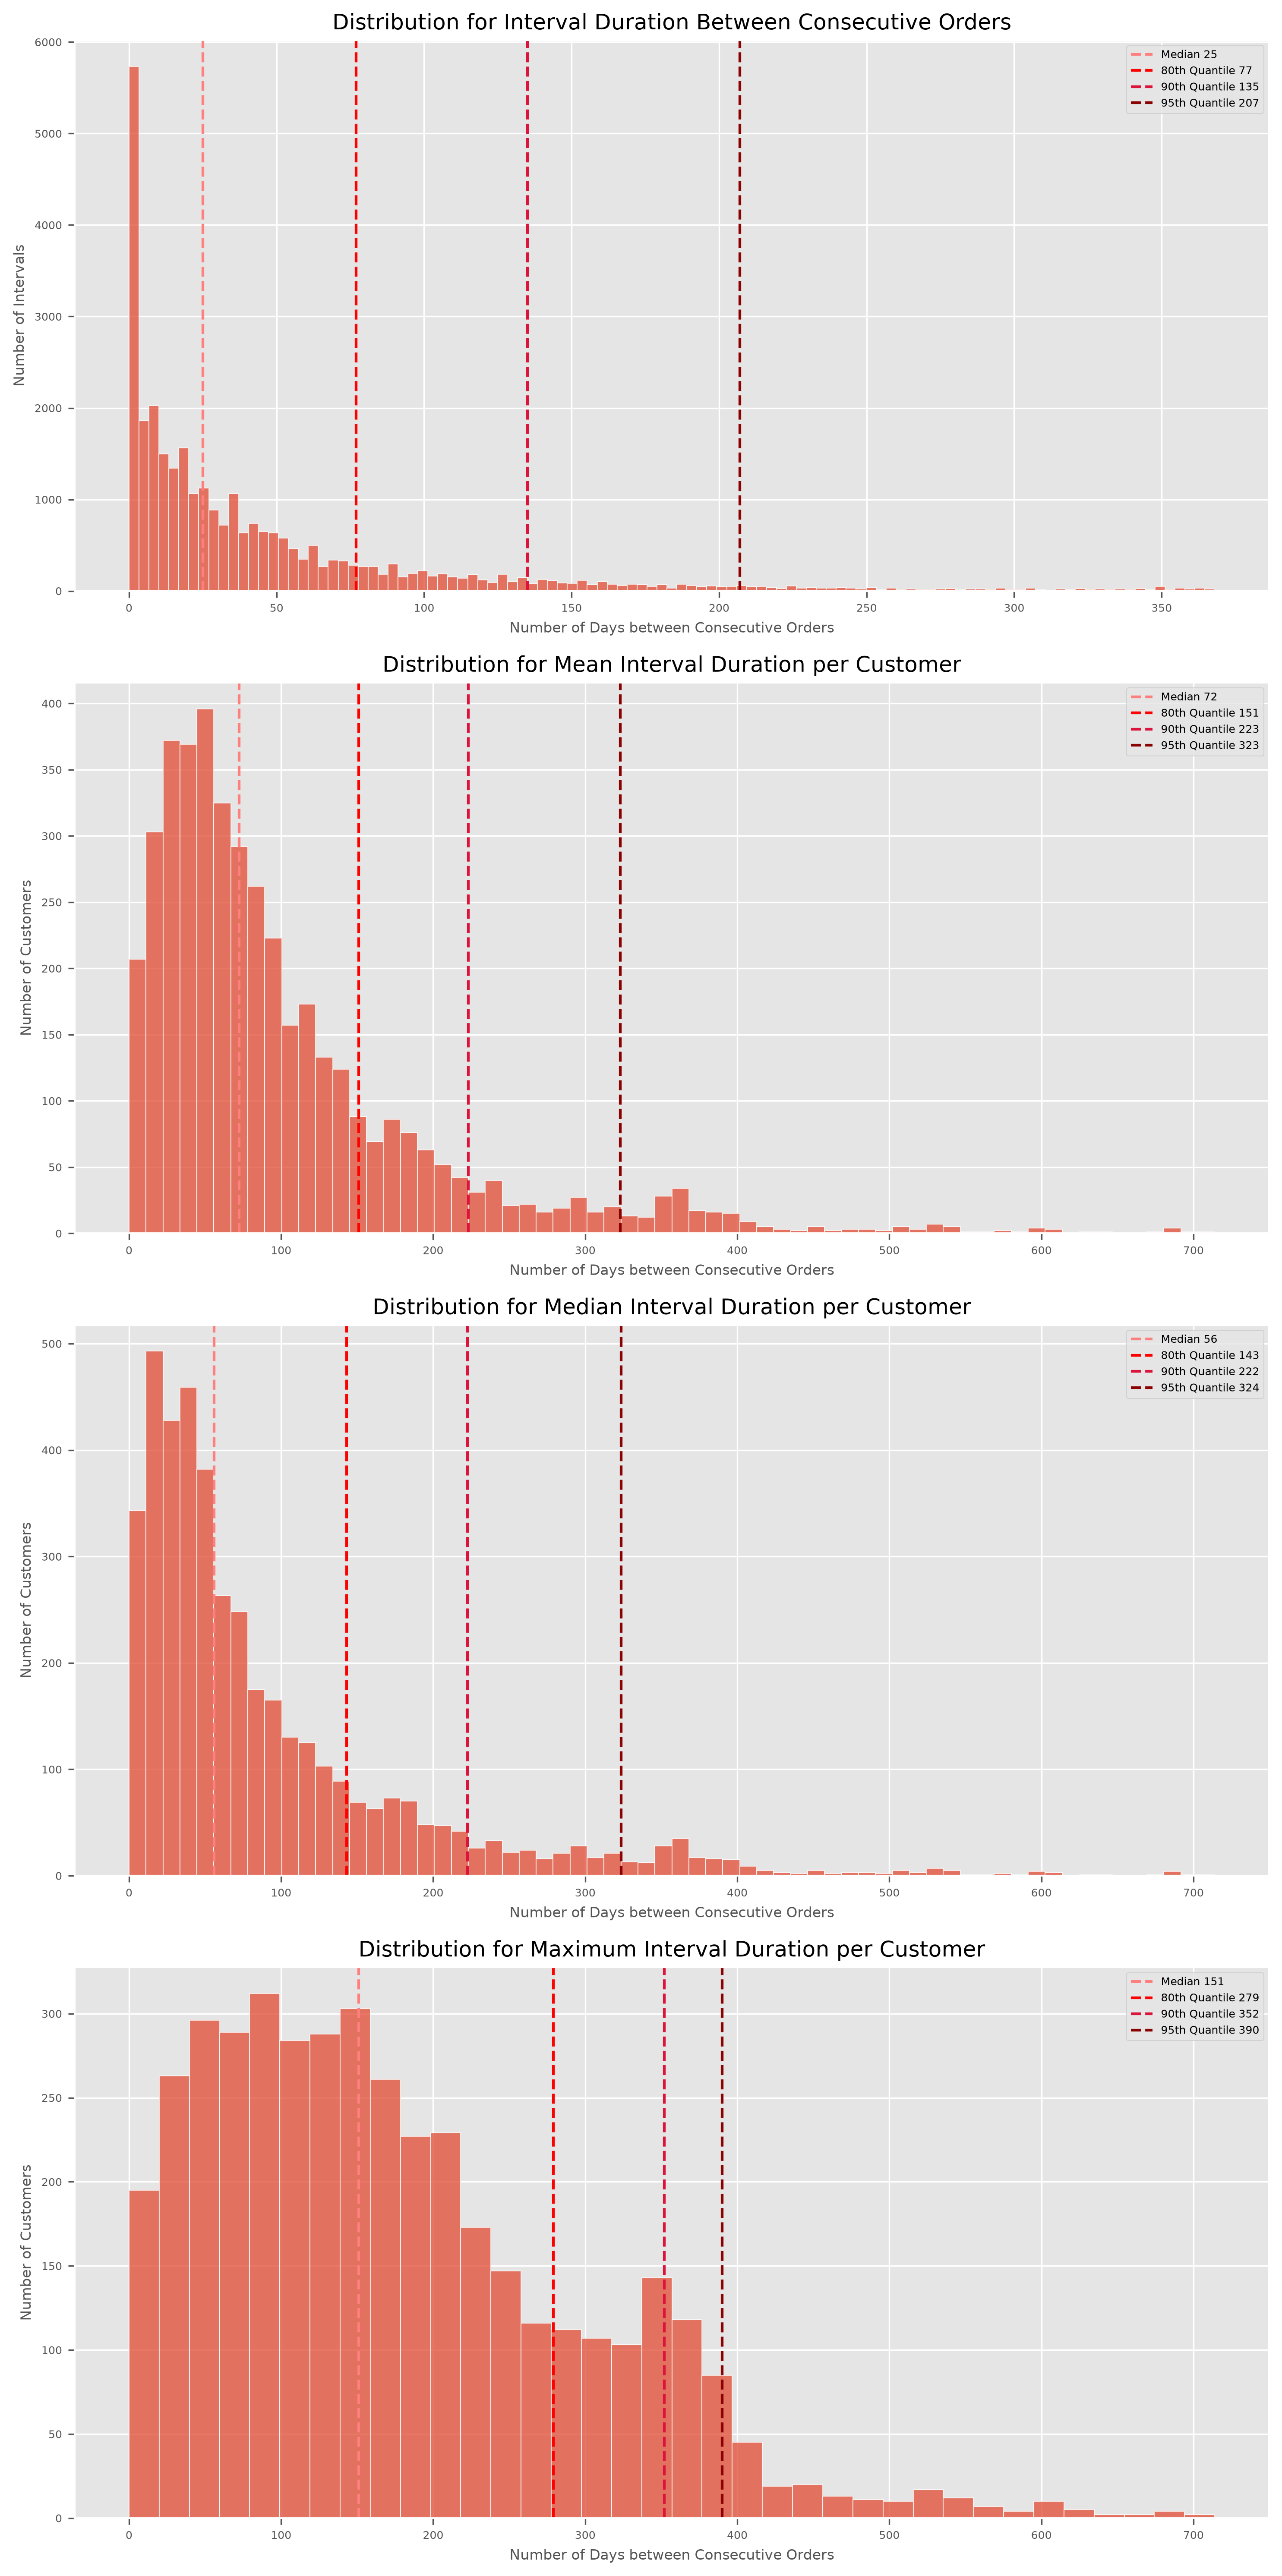

In [53]:
fig, ax = plt.subplots(4, 1, figsize=(10, 20), dpi=300)

ax[0].hist(intervals[intervals < intervals.quantile(0.99)], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax[0].set_xlabel("Number of Days between Consecutive Orders", fontsize=AXIS_LABELS)
ax[0].set_ylabel("Number of Intervals", fontsize=AXIS_LABELS)
ax[0].tick_params(axis="both", which="major", labelsize=TICKS)
ax[0].set_title("Distribution for Interval Duration Between Consecutive Orders", fontsize=GRAPH_TITLE)
ax[0].axvline(intervals.quantile(0.50), color="#FF7F7F", linestyle="--", label=f"Median {intervals.quantile(0.50):.0f}")
ax[0].axvline(intervals.quantile(0.80), color="#FF0000", linestyle="--", label=f"80th Quantile {intervals.quantile(0.80):.0f}")
ax[0].axvline(intervals.quantile(0.90), color="#DC143C", linestyle="--", label=f"90th Quantile {intervals.quantile(0.90):.0f}")
ax[0].axvline(intervals.quantile(0.95), color="#8B0000", linestyle="--", label=f"95th Quantile {intervals.quantile(0.95):.0f}")
ax[0].legend(fontsize=TICKS)

for index, series in enumerate([mean_intervals, median_intervals, max_intervals], start=1):
    ax[index].hist(series, bins="auto", alpha=0.75, edgecolor="#FFFFFF")
    ax[index].set_xlabel("Number of Days between Consecutive Orders", fontsize=AXIS_LABELS)
    ax[index].set_ylabel("Number of Customers", fontsize=AXIS_LABELS)
    ax[index].tick_params(axis="both", which="major", labelsize=TICKS)
    ax[index].axvline(series.quantile(0.50), color="#FF7F7F", linestyle="--", label=f"Median {series.quantile(0.50):.0f}")
    ax[index].axvline(series.quantile(0.80), color="#FF0000", linestyle="--", label=f"80th Quantile {series.quantile(0.80):.0f}")
    ax[index].axvline(series.quantile(0.90), color="#DC143C", linestyle="--", label=f"90th Quantile {series.quantile(0.90):.0f}")
    ax[index].axvline(series.quantile(0.95), color="#8B0000", linestyle="--", label=f"95th Quantile {series.quantile(0.95):.0f}")
    ax[index].legend(fontsize=TICKS)

ax[1].set_title("Distribution for Mean Interval Duration per Customer", fontsize=GRAPH_TITLE)
ax[2].set_title("Distribution for Median Interval Duration per Customer", fontsize=GRAPH_TITLE)
ax[3].set_title("Distribution for Maximum Interval Duration per Customer", fontsize=GRAPH_TITLE)

fig.tight_layout()

**Pooling every interval between consecutive purchases in a distribution reveals that 90% of purchases will be followed by another purchase within 135 days.** However, this figure understates the true horizon as frequency weighting lowers the quantile values. Frequent buyers will contribute disproportionately: a customer making 10 purchases in 20 days supplies 9 intervals, whilst another making a single repeat purchase after 120 days only supplies 1. **Due to this limitation, 135 days will serve as the minimum baseline value, rather than a churn horizon candidate.**

Aggregating intervals to one value per customer removes the impact of frequency weighting. **The mean and median interval distributions agree that 80% of customers will return to make a purchase within 143-151 days.** Their 90th and 95th percentiles are also congruent, but sit at 222-223 and 323-324 days, which would significantly limit the amount of usable training data. The maximum interval duration distribution presents similar signals, with a median of 151 days and higher quantiles running into the same constraint.

**Based on these results, 150 days will be adopted as a preliminary churn horizon, rounded from the 143-151 days range.** This value will be subject to adjustments within that range once model experiments commence.

#### **Selecting Cutoff Dates**

**Overview of the Machine Learning Process** 

Supervised machine learning in this project relies on the following timeframe:

| Period | Start Date | End Date | Description |
|--------|------------|----------|-------------|
| Observation Window | Day 1 | Cutoff Date | Data during this period is used for Feature Engineering. |
| Outcome Window | Cutoff Date | Churn Horizon | This period is only used to determine if the customer has churned. |

In the processed dataset, features will be determined purely using the observation window, and labels using the outcome window. The model will be learning to **classify observation windows** based on their associated labels. The model will not be examining any data from the outcome windows apart from the "churned" (0 or 1) label.

**Determining the Cutoff Dates**

5,876 customers (1 per row) does not yield much data for effective model fitting, especially after a train/test split. However, if the customer_id is dropped, the same customer can be used multiple times with different features and churned labels (based on different cutoff dates) for model training.

As the churn horizon is 150 days, the **latest cutoff date available is 2011-07-12**. Leaving 150 days before 2011-07-12 as a embargo period (aligned to a full outcome window) creates 2011-02-12 as a 2nd-latest cutoff date. To make the training windows easier to track, the last window before the test set shall be set at 2011-02-01 (start of the month). From there, decrementing until 2010-10-01 provides 5 datasets for training, with 10 months of data as lookback history.

**Cutoff Dates Selection Summary**

The following cutoff dates will be used:

Training:
- 2010-10-01
- 2010-11-01
- 2010-12-01
- 2011-01-01
- 2011-02-01

Testing:
- 2011-07-12

In [54]:
CUTOFFS = ["2010-10-01", "2010-11-01", "2010-12-01", "2011-01-01", "2011-02-01", "2011-07-12"]
HORIZON, ELIGIBILITIY_LOOKBACK = pd.Timedelta(days=150), pd.Timedelta(days=150)

for cutoff in map(pd.Timestamp, CUTOFFS):
    eligible = set(df_identified.loc[df_identified.invoice_date.between(cutoff - ELIGIBILITIY_LOOKBACK, cutoff), "customer_id"])
    active   = set(df_identified.loc[df_identified.invoice_date.between(cutoff, cutoff + HORIZON, inclusive="right"), "customer_id"])
    churned  = eligible - active
    print(f"{cutoff.date()}  eligible {len(eligible):5,}  churn {len(churned)/len(eligible):.1%}")

2010-10-01  eligible 2,712  churn 34.3%
2010-11-01  eligible 3,010  churn 39.7%
2010-12-01  eligible 3,314  churn 47.9%
2011-01-01  eligible 3,267  churn 49.0%
2011-02-01  eligible 3,162  churn 46.8%
2011-07-12  eligible 2,563  churn 30.0%


The 34-49% churn rate suggests that the churn horizon is neither too strict nor lenient, as: (1) it presents an unbalanced classification favouring retention (to be expected of e-commerce); and (2) the churn rate is not unrealistically low, which signals that long-term inactive customers are labelled as churned.

### **Frequency**

count    5853.000000
mean        6.252691
std        12.750278
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       373.000000
Name: invoice, dtype: float64


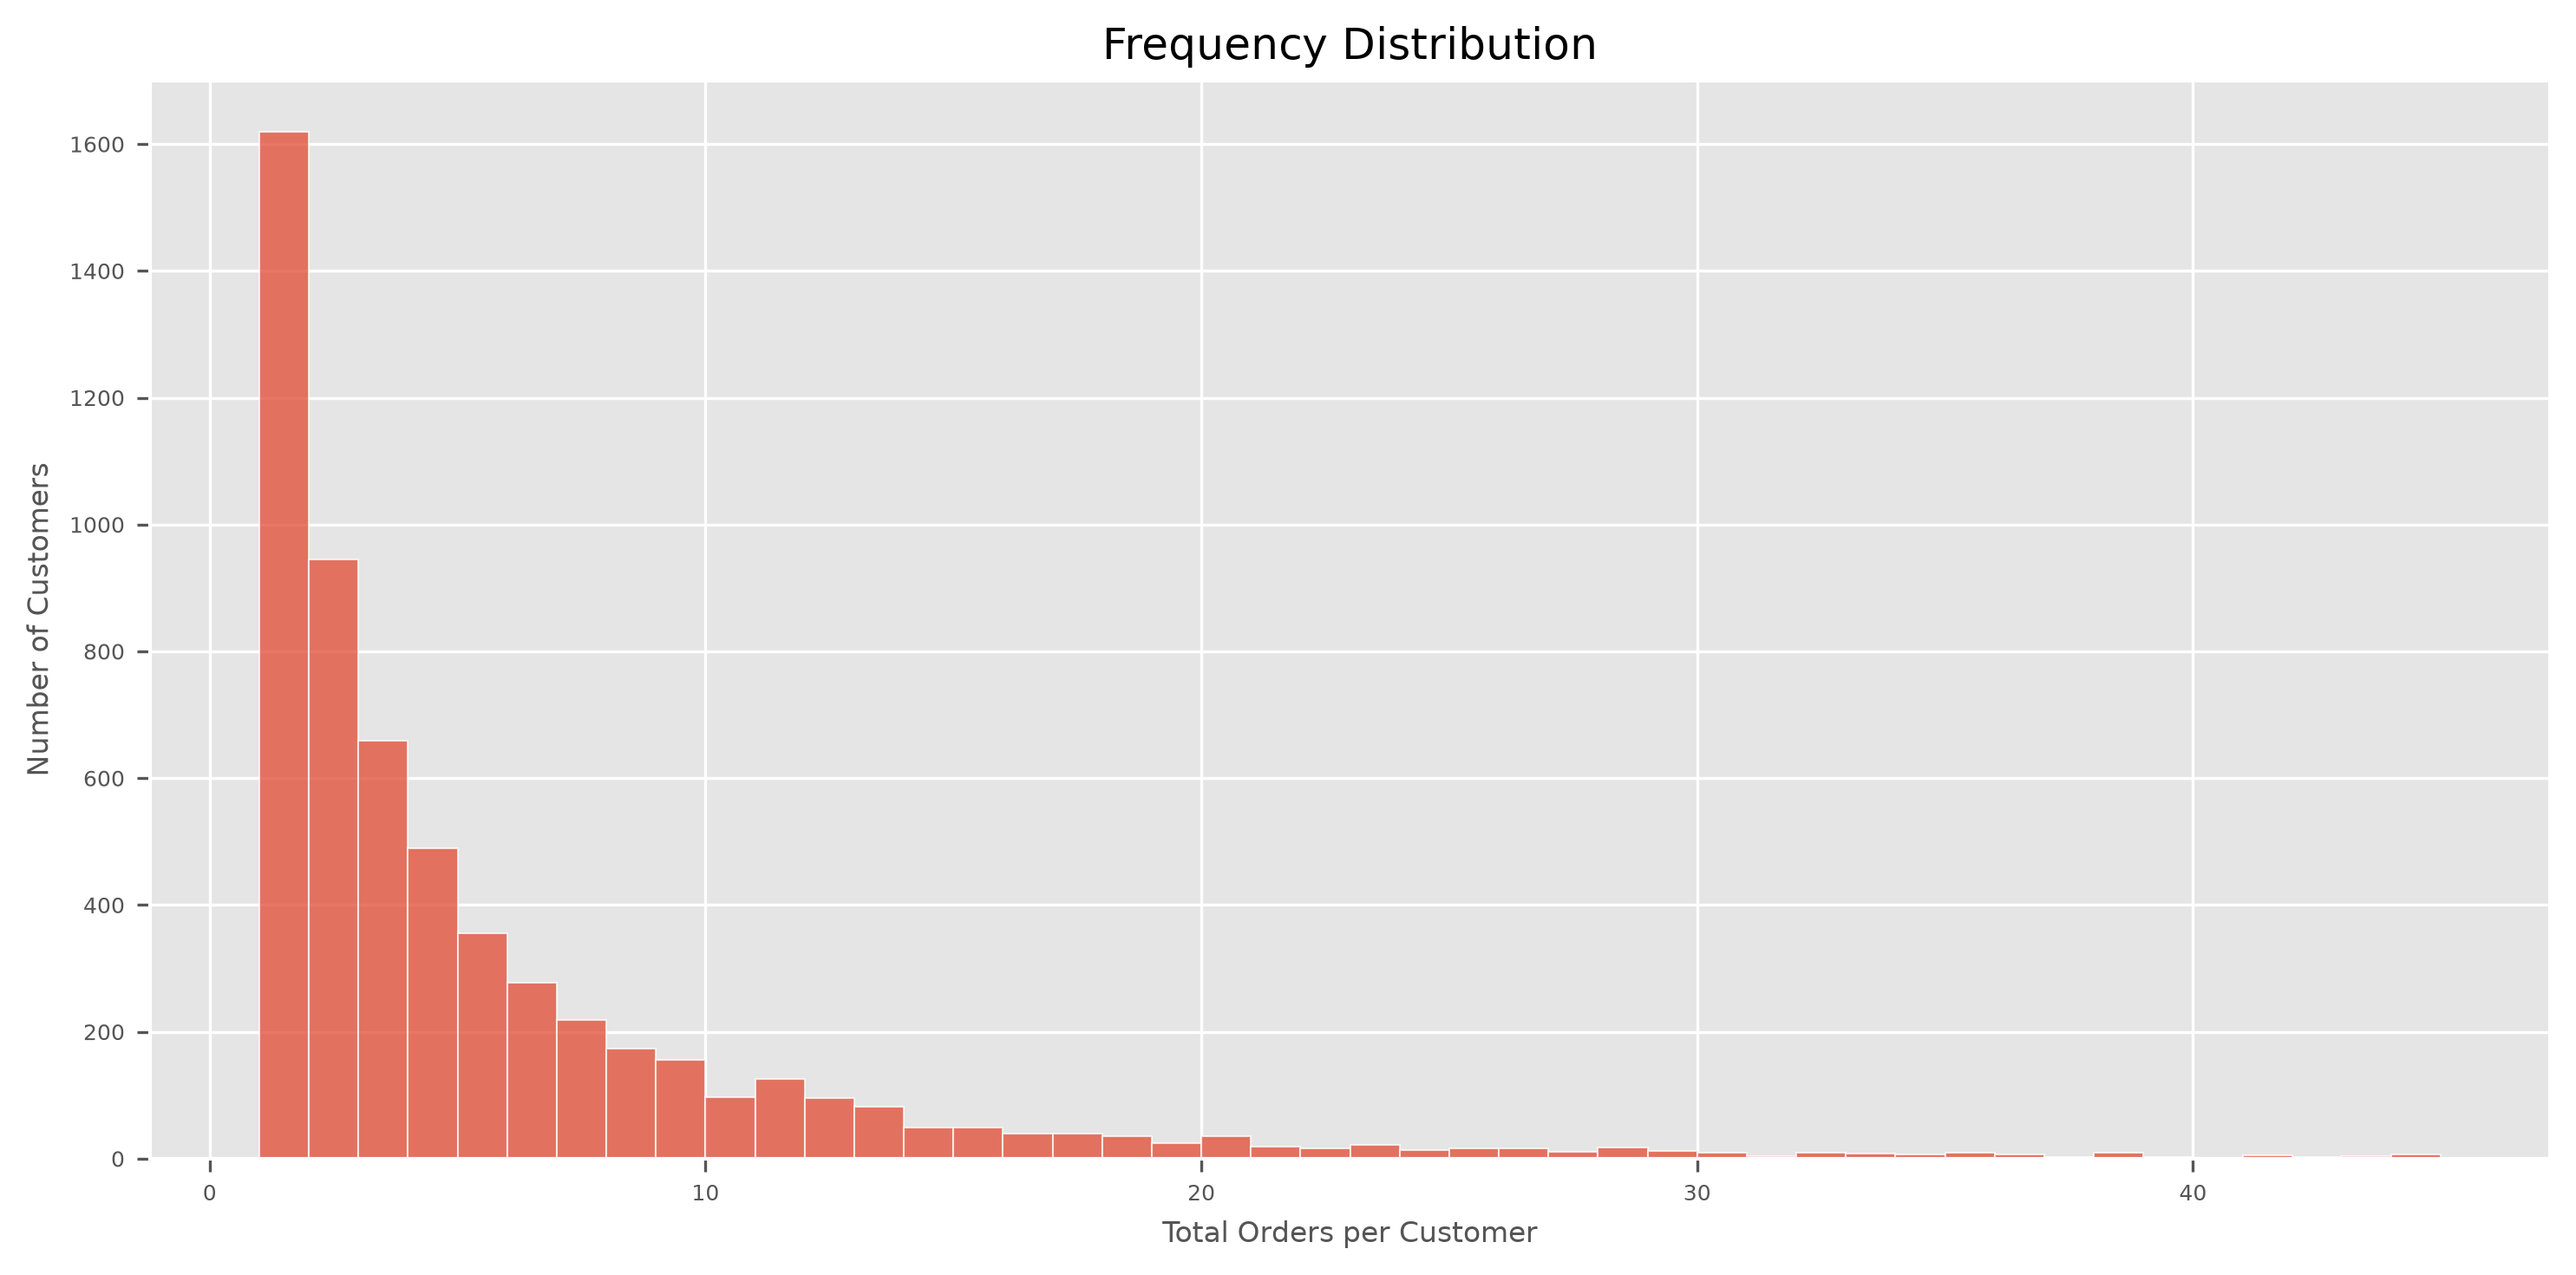

In [55]:
total_orders_per_customer = df_identified[~df_identified["invoice"].isin(str_invoices)].groupby(
    ["customer_id", "invoice"]
)["invoice_date"].min().reset_index()

total_orders_per_customer = total_orders_per_customer.drop("invoice_date", axis=1)
total_orders_per_customer = total_orders_per_customer.groupby("customer_id")["invoice"].count()
print(total_orders_per_customer.describe())

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.hist(total_orders_per_customer[
    total_orders_per_customer < total_orders_per_customer.quantile(0.99)
], bins="auto", alpha=0.75, edgecolor="#FFFFFF")
ax.set_xlabel("Total Orders per Customer", fontsize=AXIS_LABELS)
ax.set_ylabel("Number of Customers", fontsize=AXIS_LABELS)
ax.set_title("Frequency Distribution", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)
fig.tight_layout()

### **Monetary Value**

count      5853.000000
mean       2916.210958
std       14305.694223
min           0.000000
25%         339.500000
50%         856.010000
75%        2240.900000
max      580987.040000
Name: line_total, dtype: float64


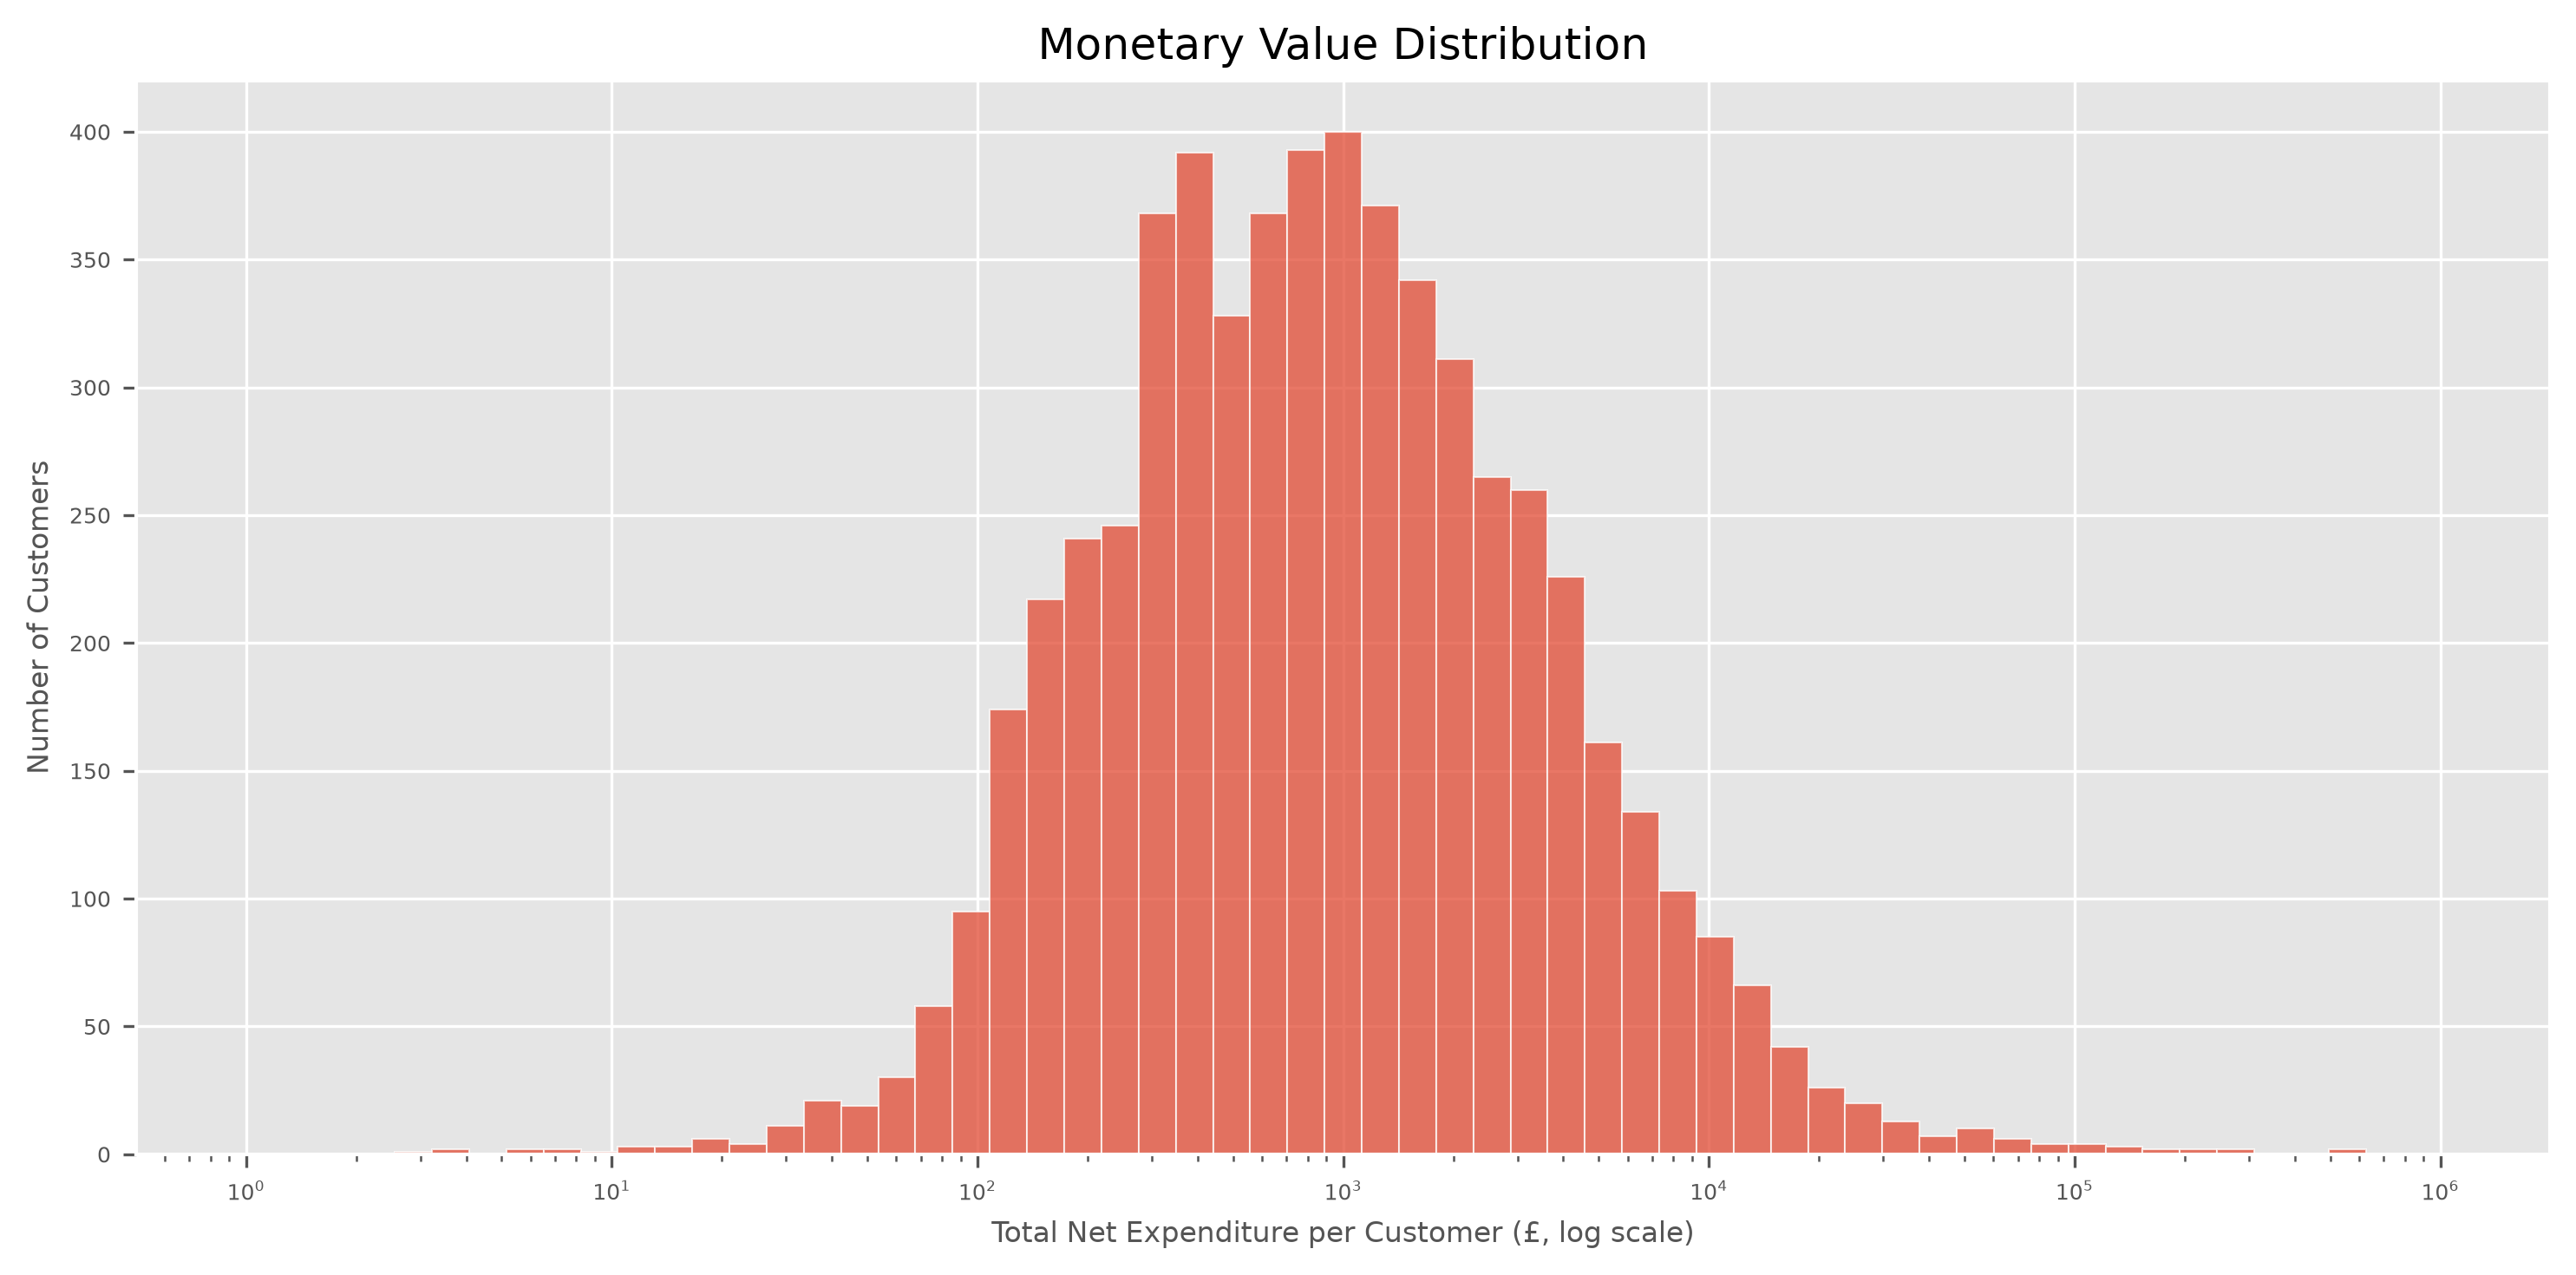

In [56]:
df_identified["line_total"] = df_identified["price"] * df_identified["quantity"]
total_expenditure_per_customer = df_identified[
    ~df_identified["invoice"].isin(str_invoices)
].groupby("customer_id")["line_total"].sum()
print(total_expenditure_per_customer.describe())

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
ax.hist(total_expenditure_per_customer, bins=np.logspace(0, 6, 60), alpha=0.75, edgecolor="#FFFFFF")
ax.set_xscale("log") # Transformed to logarithmic scale to handle skew (median £1268.20 vs max £580987.04)
ax.set_xlabel("Total Net Expenditure per Customer (£, log scale)", fontsize=AXIS_LABELS)
ax.set_ylabel("Number of Customers", fontsize=AXIS_LABELS)
ax.set_title("Monetary Value Distribution", fontsize=GRAPH_TITLE)
ax.tick_params(axis="both", which="major", labelsize=TICKS)
fig.tight_layout()

## **Determining Campaign Economics Config Values**

### **Cost Per Customer**

This value is set by the retention manager based on the actual cost of reaching out to each customer, and the overall retention campaign budget. For the purposes of this project, it will be set to **£2.50**.

### **Save Rate**

This cannot be derived from the the dataset, as not interventions are logged. As such, this will be set arbitrarily at **0.30**, with a sensitivty grid of ±0.10 (across 5 sensitivity points) computed in the expected value curve.

### **Average Customer Lifetime Value**

In [57]:
df_identified["cancelled"] = (
    df_identified["invoice"].str.startswith("C").fillna(False).astype(int)
)

df_filtered = df_identified[df_identified["cancelled"] == 0]

cutoff = pd.Timestamp("2011-02-01")
horizon = pd.Timedelta(days=150)
window = df_filtered[(df_filtered.invoice_date > cutoff) & (df_filtered.invoice_date <= cutoff + horizon)]
forward = window.groupby("customer_id")["line_total"].sum()
print(forward.describe())

count      2548.000000
mean       1095.912767
std        3716.641553
min           2.900000
25%         241.017500
50%         451.485000
75%         978.907500
max      100390.550000
Name: line_total, dtype: float64


Considering the noticeable skew between the median (£451.49) and the maximum (£100,390.55) caused by wholesalers, the mean expenditure per customer (£1,095.91) is a poor representation of a normal customer's expenditure. As such, the **median value of £451.50 (rounded to the nearest £0.10) will be set as the estimated average customer lifetime value**.

### **Campaign Capacity**

This value is also set by the retention manager, based on the campaign budget and manpower limitations in the retention outreach team. For the purposes of this project, it will be set to **500** (approximately 1/5 of the test dataset strength).

## **Important Data from EDA**

### **Configured into config.yaml and config.py**

In [58]:
# For data_prep.py (prep)
COLUMN_MAP = {
    "Invoice": "invoice",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "price",
    "Customer ID": "customer_id",
    "Country": "country",
}
NON_PRODUCT = ["POST", "D", "M", "C2", "BANK CHARGES", "TEST001", "TEST002", "ADJUST", "ADJUST2", "DOT", "CRUK"]

In [59]:
# For labelling.py (labelling)
CUTOFFS = ["2010-10-01", "2010-11-01", "2010-12-01", "2011-01-01", "2011-02-01", "2011-07-12"]
CHURN_HORIZON = 150
ELIGIBILITY_LOOKBACK = 150
MINIMUM_TRANSACTIONS = 1 # Identified customers with 1 purchase are still churned customers

In [60]:
# For train.py (model)
TEST_CUTOFF = "2011-07-12"

In [61]:
# For economics.py (economics)
COST_PER_CONTACT = 2.50
AVERAGE_CUSTOMER_LIFETIME_VALUE = 451.50
SAVE_RATE = 0.30
SENSITIVITY_SPREAD = 0.10
SENSITIVITY_POINTS = 5
CAMPAIGN_CAPACITY = 500

### **Cross Validation for Rows Dropped**

**Total rows before all of the drops:** 1067371

| Description | Number of Rows Dropped |
|-------------|------------------------|
| Drop all duplicates | 34335 |
| Drop unidentified customers | 235151 |
| Drop non-product line-item purchases | 3641 |

**Total rows left after all of the drops:** 794244